# Práctica 2 — Optimización estocástica
## Inversión multietapa con datos de mercado

**Universidad EAFIT · Semestre 2026-2**  
**Profesor:** Diego Fonseca  
**Integrantes:** Jaime Andres Jaramillo y Santiago Vera Ramirez.

En esta práctica buscamos una política de inversión para una fundación que dispone de USD 100.000 al finalizar diciembre de 2025 y necesita USD 106.000 en septiembre de 2026. Podemos invertir en SPY, LQD y GLD y rebalancear al terminar marzo y junio.

Trabajamos en **miles de dólares** y minimizamos el costo esperado de cuatro veces el déficit menos el exceso. Calibramos con información hasta 2025 y reservamos 2026 para evaluar la política obtenida.

### Cómo ejecutar

Ejecutar las celdas en orden en Google Colab. Las explicaciones están en celdas de texto; las celdas de código contienen las operaciones. Al finalizar se genera un ZIP con datos, tablas y figuras.

Este archivo se entrega sin resultados de mercado precalculados. La descarga y la solución se realizan al ejecutarlo. Si faltan datos o no se alcanza la tolerancia, la ejecución se detiene.

## 1. Preparación del entorno

Instalamos las herramientas necesarias. Usamos SciPy con HiGHS para resolver los programas lineales y obtener sus multiplicadores duales. No utilizamos procedimientos aleatorios, por lo que no se requiere semilla.

In [ ]:
%pip -q install yfinance pandas_market_calendars scipy pandas numpy matplotlib

In [ ]:
from pathlib import Path
from itertools import product
from datetime import datetime, timezone
from time import perf_counter
import importlib.metadata
import json
import shutil
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
import pandas_market_calendars as mcal
from scipy.optimize import linprog
from IPython.display import display

ACTIVOS = ["SPY", "LQD", "GLD"]
B, M, LAM = 100.0, 106.0, 4.0
TOL_REL, TOL_FACT, TOL_META = 1e-6, 1e-7, 1e-6
MAX_CICLOS = 500
ESTADOS_POSIBLES = ["".join(x) for x in product("AB", repeat=3)]
CARPETA = Path("/content/practica2_resultados")
CARPETA.mkdir(parents=True, exist_ok=True)
REGISTRO_DESCARGAS = []
pd.set_option("display.max_columns", 30)
pd.set_option("display.precision", 6)
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True})

def guardar_tabla(df, nombre, index=False):
    df.to_csv(CARPETA / f"{nombre}.csv", index=index)

def guardar_figura(nombre):
    plt.tight_layout()
    plt.savefig(CARPETA / f"{nombre}.png", dpi=180, bbox_inches="tight")
    plt.show()

def resolver_lp(**kwargs):
    res = linprog(method="highs", options={
        "primal_feasibility_tolerance": 1e-9,
        "dual_feasibility_tolerance": 1e-9}, **kwargs)
    if not res.success:
        raise RuntimeError(f"No se pudo resolver un LP: {res.message}")
    return res

def estado_de(r):
    return "".join("B" if v < 0 else "A" for v in r)

def historia_texto(h):
    return "Raíz" if not h else " → ".join(h)

def prob_historia(h, q):
    return float(np.prod([q[u] for u in h])) if h else 1.0

def costo_terminal(v):
    v = np.asarray(v)
    return LAM * np.maximum(M-v, 0) - np.maximum(v-M, 0)

def verificar_inversion(x, riqueza):
    assert np.min(x) >= -TOL_FACT, "Inversión negativa."
    assert np.isclose(np.sum(x), riqueza, atol=TOL_FACT, rtol=1e-9), "Balance incumplido."

print({"capital_inicial": B, "meta": M, "penalizacion": LAM})

{'capital_inicial': 100.0, 'meta': 106.0, 'penalizacion': 4.0}


## 2. Datos de calibración

Descargamos **Adj Close** de Yahoo Finance con `auto_adjust=False`, para identificar expresamente el precio ajustado. Conservamos el último cierre bursátil de diciembre de 2009 y de cada trimestre de 2010–2025: 65 precios y 64 rendimientos por activo.

Verificamos las fechas con el calendario NYSE. No rellenamos precios faltantes ni sustituimos un cierre trimestral por una cotización anterior. La fecha final de la consulta es exclusiva. Si Yahoo limita la consulta, debemos reintentarlo.

$$r_{i,j}=\frac{P_{i,j}}{P_{i,j-1}}-1,\qquad R_{i,j}=1+r_{i,j}.$$

En los balances usamos $R$, no $r$. Los ajustes ya incorporan los pagos correspondientes; no los sumamos nuevamente. Los datos de validación se descargarán después de guardar la política.

In [ ]:
def descargar_trimestrales(inicio, fin_exclusivo, periodos, etiqueta):
    agenda = mcal.get_calendar("NYSE").schedule(
        start_date=inicio, end_date=pd.Timestamp(fin_exclusivo)-pd.Timedelta(days=1))
    sesiones = pd.DatetimeIndex(agenda.index).tz_localize(None).normalize()
    fechas = []
    for periodo in periodos:
        candidatas = sesiones[sesiones.to_period("Q") == periodo]
        if len(candidatas) == 0:
            raise ValueError(f"Sin sesiones para {periodo}.")
        fechas.append(candidatas[-1])
    precios = pd.DataFrame(index=pd.DatetimeIndex(fechas, name="fecha"))
    for activo in ACTIVOS:
        datos = yf.Ticker(activo).history(
            start=inicio, end=fin_exclusivo, interval="1d",
            auto_adjust=False, actions=False)
        if datos.empty or "Adj Close" not in datos.columns:
            raise RuntimeError(f"Yahoo no entregó Adj Close para {activo}. Reintentar la consulta.")
        indice = pd.DatetimeIndex(datos.index)
        if indice.tz is not None:
            indice = indice.tz_convert("America/New_York").tz_localize(None)
        datos.index = indice.normalize()
        assert not datos.index.duplicated().any(), "Fechas duplicadas."
        serie = datos["Adj Close"].reindex(precios.index)
        if serie.isna().any():
            faltan = serie.index[serie.isna()].strftime("%Y-%m-%d").tolist()
            raise ValueError(f"Faltan cierres de {activo}: {faltan}. No se reemplazarán.")
        assert np.isfinite(serie).all() and (serie > 0).all()
        precios[activo] = serie.astype(float)
        REGISTRO_DESCARGAS.append({
            "bloque": etiqueta, "activo": activo, "fuente": "Yahoo Finance",
            "herramienta": "yfinance", "campo": "Adj Close", "auto_adjust": False,
            "inicio": inicio, "fin_exclusivo": fin_exclusivo,
            "consulta_UTC": datetime.now(timezone.utc).isoformat()})
    guardar_tabla(precios, f"cierres_{etiqueta}", index=True)
    return precios

P_cal = descargar_trimestrales("2009-12-01", "2026-01-01",
    pd.period_range("2009Q4", "2025Q4", freq="Q"), "calibracion")
r_cal = P_cal.pct_change(fill_method=None).iloc[1:]
R_cal = 1+r_cal
assert P_cal.shape == (65, 3) and r_cal.shape == (64, 3)
assert np.isfinite(R_cal.to_numpy()).all() and (R_cal.to_numpy() > 0).all()
guardar_tabla(r_cal, "rendimientos_calibracion", index=True)
guardar_tabla(R_cal, "factores_calibracion", index=True)
display(P_cal.head())
print("Calibración:", len(P_cal), "precios y", len(r_cal), "rendimientos por activo.")

,SPY,LQD,GLD
fecha,,,
2009-12-31,82.961960,56.205444,107.309998
2010-03-31,87.459816,57.568184,108.949997
2010-06-30,77.526077,59.797165,121.680000
2010-09-30,86.179245,63.089508,127.910004
2010-12-31,95.452827,61.441830,138.720001


Calibración: 65 precios y 64 rendimientos por activo.


### 2.1. Estadísticas y evolución de precios

Calculamos la media, desviación estándar muestral, mínimo y máximo de los 64 rendimientos. Normalizamos los precios a 100 en diciembre de 2009 para comparar su evolución en una misma escala. Las estadísticas no incorporan 2026.

,Media,Desviación estándar,Mínimo,Máximo
SPY,0.036118,0.074367,-0.194477,0.201618
LQD,0.010692,0.037009,-0.084033,0.100979
GLD,0.023560,0.076929,-0.228812,0.190022


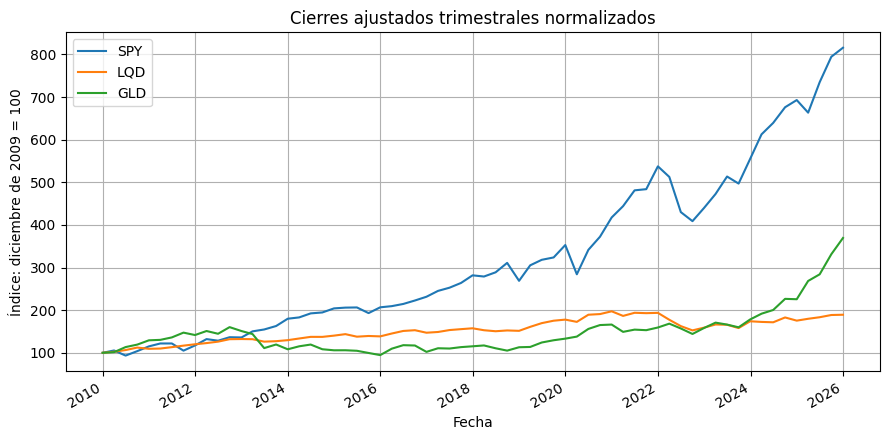

In [ ]:
estadisticas = r_cal.agg(["mean", "std", "min", "max"]).T
estadisticas.columns = ["Media", "Desviación estándar", "Mínimo", "Máximo"]
display(estadisticas)
guardar_tabla(estadisticas, "estadisticas_rendimientos", index=True)
normalizados = 100*P_cal/P_cal.iloc[0]
normalizados.plot()
plt.ylabel("Índice: diciembre de 2009 = 100")
plt.xlabel("Fecha")
plt.title("Cierres ajustados trimestrales normalizados")
guardar_figura("precios_normalizados")

## 3. Estados conjuntos

Clasificamos los signos en el orden **SPY, LQD, GLD**: A significa rendimiento no negativo y B significa negativo.

$$\widehat q_u=\frac{n_u}{64},\qquad \widehat R_i(u)=\frac{1}{n_u}\sum_{j\in J_u}R_{i,j}.$$

Contamos las coincidencias de los tres signos en un mismo trimestre. No multiplicamos probabilidades marginales, porque no suponemos independencia entre activos.

El enunciado indica que aparecen los ocho estados. Si algún estado está vacío, el código se detiene para revisar fechas y ajustes. Solo después de verificar que la ausencia persiste se puede cambiar `AUSENCIA_VERIFICADA` a `True`, documentar esa revisión y eliminar la rama.

In [ ]:
clasificacion = r_cal.copy()
clasificacion["estado"] = [estado_de(fila) for fila in r_cal.to_numpy()]
filas = []
for u in ESTADOS_POSIBLES:
    mascara = clasificacion.estado.eq(u)
    n = int(mascara.sum())
    filas.append({"estado": u, "conteo": n, "probabilidad": n/64,
        **{f"R_{a}": R_cal.loc[mascara, a].mean() if n else np.nan for a in ACTIVOS}})
tabla_estados = pd.DataFrame(filas)
display(tabla_estados)
guardar_tabla(tabla_estados, "estados_conjuntos")
guardar_tabla(clasificacion, "clasificacion_historica", index=True)
ausentes = tabla_estados.loc[tabla_estados.conteo.eq(0), "estado"].tolist()
AUSENCIA_VERIFICADA = False
if ausentes and not AUSENCIA_VERIFICADA:
    raise ValueError(f"Estados vacíos: {ausentes}. Revisar fechas y ajustes antes de continuar.")
estados = tabla_estados.loc[tabla_estados.conteo.gt(0), "estado"].tolist()
q = tabla_estados.set_index("estado").loc[estados, "probabilidad"].to_dict()
R = {u: tabla_estados.set_index("estado").loc[u,
    [f"R_{a}" for a in ACTIVOS]].to_numpy(dtype=float) for u in estados}
assert sum(tabla_estados.conteo) == 64 and np.isclose(sum(q.values()), 1)
assert all(np.all(R[u] > 0) for u in estados)

,estado,conteo,probabilidad,R_SPY,R_LQD,R_GLD
0,AAA,31,0.484375,1.070526,1.034144,1.065740
1,AAB,6,0.093750,1.069237,1.020278,0.963796
2,ABA,3,0.046875,1.085100,0.986718,1.068594
3,ABB,11,0.171875,1.043089,0.977068,0.931211
4,BAA,3,0.046875,0.901859,1.031670,1.129822
5,BAB,3,0.046875,0.967833,1.014010,0.950266
6,BBA,4,0.062500,0.903526,0.962917,1.046330
7,BBB,3,0.046875,0.919115,0.935849,0.937469


### 3.1. Árbol de escenarios

Suponemos que los estados de trimestres distintos son independientes y siguen la misma distribución. Entonces:

$$P(z_1,z_2,z_3)=\widehat q_{z_1}\widehat q_{z_2}\widehat q_{z_3}.$$

Con ocho estados tenemos 1, 8, 64 y 512 nodos por etapa. Las primeras tres etapas son de inversión y la cuarta es terminal. Usamos $a(k)$ para el padre, $C_{t+1}(k)$ para los hijos, $\omega_k^t$ para la historia y $p_k^t$ para la probabilidad acumulada.

La probabilidad condicional de cada rama es $q_{\ell\mid k}=p_\ell^{t+1}/p_k^t$. Exportamos todos los nodos y mostramos las ramas de la raíz y de un nodo de etapa 2.

Nodos por etapa: [1, 8, 64, 512]
Total de nodos: 585


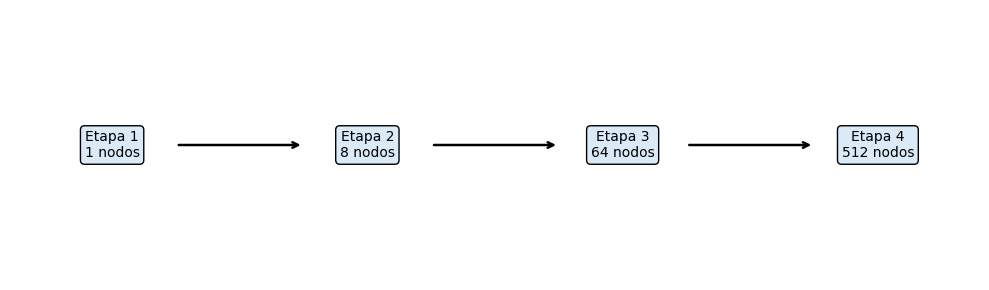

,padre,hijo,q_condicional,p_acumulada,R_SPY,R_LQD,R_GLD
0,Raíz,AAA,0.484375,0.484375,1.070526,1.034144,1.065740
1,Raíz,AAB,0.093750,0.093750,1.069237,1.020278,0.963796
2,Raíz,ABA,0.046875,0.046875,1.085100,0.986718,1.068594
3,Raíz,ABB,0.171875,0.171875,1.043089,0.977068,0.931211
4,Raíz,BAA,0.046875,0.046875,0.901859,1.031670,1.129822
5,Raíz,BAB,0.046875,0.046875,0.967833,1.014010,0.950266
6,Raíz,BBA,0.062500,0.062500,0.903526,0.962917,1.046330
7,Raíz,BBB,0.046875,0.046875,0.919115,0.935849,0.937469


,padre,hijo,q_condicional,p_acumulada,R_SPY,R_LQD,R_GLD
0,AAA,AAA → AAA,0.484375,0.234619,1.070526,1.034144,1.065740
1,AAA,AAA → AAB,0.093750,0.045410,1.069237,1.020278,0.963796
2,AAA,AAA → ABA,0.046875,0.022705,1.085100,0.986718,1.068594
3,AAA,AAA → ABB,0.171875,0.083252,1.043089,0.977068,0.931211
4,AAA,AAA → BAA,0.046875,0.022705,0.901859,1.031670,1.129822
5,AAA,AAA → BAB,0.046875,0.022705,0.967833,1.014010,0.950266
6,AAA,AAA → BBA,0.062500,0.030273,0.903526,0.962917,1.046330
7,AAA,AAA → BBB,0.046875,0.022705,0.919115,0.935849,0.937469


In [ ]:
def niveles_arbol(estados_locales):
    return [list(product(estados_locales, repeat=d)) for d in range(4)]

niveles = niveles_arbol(estados)
ids = {h: k for nivel in niveles for k, h in enumerate(nivel, start=1)}
tabla_nodos = pd.DataFrame([
    {"etapa": d+1, "nodo": ids[h], "historia": historia_texto(h),
     "padre": ids[h[:-1]] if h else None,
     "probabilidad": prob_historia(h, q),
     "probabilidad_condicional": q[h[-1]] if h else 1}
    for d, nivel in enumerate(niveles) for h in nivel])
guardar_tabla(tabla_nodos, "arbol_completo")
for t in range(1, 5):
    assert np.isclose(tabla_nodos.loc[tabla_nodos.etapa.eq(t), "probabilidad"].sum(), 1)
print("Nodos por etapa:", [len(n) for n in niveles])
print("Total de nodos:", len(tabla_nodos))
fig, ax = plt.subplots(figsize=(10, 3))
ax.axis("off")
for d, nivel in enumerate(niveles):
    x = d*3
    ax.text(x, 0, f"Etapa {d+1}\n{len(nivel)} nodos", ha="center", va="center",
            bbox=dict(boxstyle="round", facecolor="#daeaf6"))
    if d < 3:
        ax.annotate("", xy=(x+2.25, 0), xytext=(x+.75, 0),
                    arrowprops=dict(arrowstyle="->", lw=1.8))
ax.set_xlim(-1.2, 10.2)
ax.set_ylim(-1, 1)
guardar_figura("esquema_arbol")

def detallar_ramas(h):
    return pd.DataFrame([{
        "padre": historia_texto(h), "hijo": historia_texto(h+(u,)),
        "q_condicional": q[u], "p_acumulada": prob_historia(h+(u,), q),
        **dict(zip([f"R_{a}" for a in ACTIVOS], R[u]))} for u in estados])

ramas_raiz = detallar_ramas(())
ramas_etapa2 = detallar_ramas((estados[0],))
display(ramas_raiz, ramas_etapa2)
guardar_tabla(ramas_raiz, "ramas_raiz")
guardar_tabla(ramas_etapa2, "ramas_nodo_etapa2")

## 4. Formulación matemática

Sea $x_{i,k}^t\geq0$ el dinero invertido en el activo $i$ del nodo $(t,k)$ para $t=1,2,3$. La riqueza es $V_k^t=\sum_i x_{i,k}^t$. En las hojas, $y_k^4\geq0$ es el exceso y $w_k^4\geq0$ es el déficit.

$$\min\sum_{k=1}^{K_4}p_k^4(4w_k^4-y_k^4)$$

sujeto a:

$$\sum_i x_{i,1}^1=b,$$

$$\sum_i x_{i,k}^t=\sum_i\widehat R_i(u_k)x_{i,a(k)}^{t-1},\qquad t=2,3,$$

$$\sum_i\widehat R_i(u_k)x_{i,a(k)}^3-y_k^4+w_k^4=M.$$

Toda la riqueza se invierte; no hay préstamos, aportes adicionales, ventas en corto, impuestos ni comisiones. Las variables son continuas. No imponemos $V_k^4\geq M$: el modelo permite incumplir y lo penaliza.

Con ocho estados, el equivalente determinista tiene $3(73)+2(512)=1243$ variables y 585 igualdades. Conserva todos los nodos y no reemplaza los rendimientos por medias.

### No anticipatividad

Las trayectorias (AAA, AAA, AAA) y (AAA, BBB, BBB), cuando esos estados tienen soporte, comparten la decisión inicial y la decisión posterior al primer AAA. En ese momento todavía no conocemos el segundo estado. Solo podemos distinguir decisiones cuando las historias observadas se separan. Una única variable por nodo incorpora esta condición.

### Matrices de enlace

Mantenemos la forma de clase:

$$T_{t-1,k}x_{a(k)}^{t-1}+W_tx_k^t=h_k^t.$$

En un nodo intermedio:

$$T_{t-1,k}=-\widehat R(u_k)^\top,\quad W_t=(1,1,1),\quad h_k^t=0.$$

En una hoja, con $x_k^4=(y_k^4,w_k^4)^\top$:

$$T_{3,k}=\widehat R(u_k)^\top,\quad W_4=(-1,1),\quad h_k^4=M.$$

$W_t$ es una matriz; no debe confundirse con la riqueza $V_k^t$ o el déficit $w_k^4$.

### Problema terminal y dual

Dada una riqueza $V$:

$$\min_{y,w\geq0}\{-y+4w:-y+w=M-V\}.$$

Su dual es:

$$\max_\pi\{(M-V)\pi:1\leq\pi\leq4\}.$$

Si $V<M$, un dual óptimo es 4; si $V>M$, es 1. Si $V=M$, cualquier valor de $[1,4]$ es óptimo. Verificamos dualidad fuerte y el signo del multiplicador: como el lado derecho es $M-V$, la derivada respecto a $V$ es $-\pi$.

In [ ]:
def terminal_lp(riqueza):
    res = resolver_lp(c=[-1.0, LAM], A_eq=[[-1.0, 1.0]],
        b_eq=[M-riqueza], bounds=[(0, None), (0, None)])
    pi = float(res.eqlin.marginals[0])
    assert 1-1e-7 <= pi <= LAM+1e-7
    assert np.isclose(res.fun, (M-riqueza)*pi, atol=1e-7)
    assert np.isclose(res.fun, costo_terminal(riqueza), atol=1e-7)
    return float(res.fun), pi

for riqueza in [M-2, M+2]:
    valor, pi = terminal_lp(riqueza)
    eps = 1e-4
    perturbado, _ = terminal_lp(riqueza+eps)
    derivada = (perturbado-valor)/eps
    assert np.isclose(derivada, -pi, atol=1e-5)
    print(f"V={riqueza:.2f}; costo={valor:.2f}; dual={pi:.2f}; derivada={derivada:.2f}")

V=104.00; costo=8.00; dual=4.00; derivada=-4.00
V=108.00; costo=-2.00; dual=1.00; derivada=-1.00


### Recurso relativamente completo y cota inicial

Las inversiones no negativas y los factores positivos producen riqueza no negativa. Siempre podemos distribuirla entre los tres activos. Cualquier diferencia terminal respecto a la meta puede expresarse mediante exceso o déficit. Por eso no necesitamos cortes de factibilidad.

Definimos:

$$R_{\max}=\max\{1,\max_{i,u}\widehat R_i(u)\},\qquad L=\min\{0,M-bR_{\max}^3\}.$$

En cada trimestre, la riqueza puede multiplicarse como máximo por $R_{\max}$. Entonces la riqueza terminal alcanzable está acotada por $bR_{\max}^3$. El costo terminal es al menos $M-V$, de modo que $L$ es una cota inferior válida del costo futuro en nodos alcanzables. Inicializamos $\theta_k^t\geq L$ permitiendo valores negativos.

## 5. Algoritmo L-shaped anidado

Cada nodo no terminal tiene un maestro local $NLDS(t,k)$ que minimiza $\theta_k^t$, porque no hay costo inmediato. Las hojas solo tienen costo terminal.

En la **pasada hacia adelante** recorremos todo el árbol y fijamos en cada hijo la inversión de su padre. Evaluamos esa política completa con las probabilidades y costos de todas las hojas. Conservamos la política del mejor $UB$.

En la **pasada hacia atrás** recorremos etapas 3, 2 y 1. Cuando un hijo intermedio recibe cortes, lo resolvemos de nuevo en el punto heredado antes de usar sus duales. Para cada hijo:

$$\beta_\ell=-T_{t,\ell}^\top\pi_\ell,\qquad
\alpha_\ell=v_\ell(\bar x)-\beta_\ell^\top\bar x.$$

El valor $v_\ell$ incluye la aproximación al futuro y todos los cortes actuales. El corte agregado es:

$$\theta_k^t\geq\sum_{\ell\in C_{t+1}(k)}q_{\ell\mid k}
\left(\alpha_\ell+\beta_\ell^\top x_k^t\right).$$

En la notación de clase, $E x+\theta\geq e$, donde $E=-\beta^\top$ y $e=\alpha$. Para SciPy escribimos $\beta^\top x-\theta\leq-\alpha$.

Los objetivos locales no se multiplican por probabilidades acumuladas. Guardamos todos los cortes y calculamos $LB$ resolviendo la raíz después de la pasada hacia atrás. Detenemos cuando:

$$\frac{UB-LB}{\max\{1,|UB|,|LB|\}}\leq10^{-6}.$$

El límite de ciclos evita una ejecución indefinida; alcanzarlo sin convergencia genera un error y no una certificación.

In [ ]:
def evaluar_hojas(politica, estados_locales, q_local, R_local):
    filas = []
    for h in product(estados_locales, repeat=3):
        riqueza = float(R_local[h[-1]] @ politica[h[:-1]])
        exceso, deficit = max(riqueza-M, 0), max(M-riqueza, 0)
        filas.append({"historia": historia_texto(h), "probabilidad": prob_historia(h, q_local),
            "riqueza": riqueza, "exceso": exceso, "deficit": deficit,
            "costo": LAM*deficit-exceso, "cumple_meta": int(riqueza >= M-TOL_META)})
    return pd.DataFrame(filas)

def lshaped(estados_locales, q_local, R_local, etiqueta):
    niveles_locales = niveles_arbol(estados_locales)
    decisiones = [h for nivel in niveles_locales[:3] for h in nivel]
    rmax = max(1.0, max(np.max(R_local[u]) for u in estados_locales))
    L = min(0.0, M-B*rmax**3)
    cortes = {h: [] for h in decisiones}
    bitacora_cortes, registro = [], []
    mejor_ub, mejor_politica = np.inf, None
    inicio = perf_counter()

    def local(h, riqueza):
        acumulados = cortes[h]
        A_ub = np.array([np.r_[beta, -1.] for alpha, beta in acumulados]) if acumulados else None
        b_ub = np.array([-alpha for alpha, beta in acumulados]) if acumulados else None
        return resolver_lp(c=[0, 0, 0, 1], A_eq=[[1, 1, 1, 0]], b_eq=[riqueza],
            A_ub=A_ub, b_ub=b_ub, bounds=[(0, None)]*3+[(L, None)])

    for ciclo in range(1, MAX_CICLOS+1):
        politica = {}
        for nivel in niveles_locales[:3]:
            for h in nivel:
                riqueza = B if not h else float(R_local[h[-1]] @ politica[h[:-1]])
                solucion = local(h, riqueza)
                x = solucion.x[:3].copy()
                verificar_inversion(x, riqueza)
                politica[h] = x
        hojas = evaluar_hojas(politica, estados_locales, q_local, R_local)
        costo_politica = float(hojas.probabilidad @ hojas.costo)
        if costo_politica < mejor_ub:
            mejor_ub = costo_politica
            mejor_politica = {h: x.copy() for h, x in politica.items()}
        for profundidad in [2, 1, 0]:
            for h in niveles_locales[profundidad]:
                xbar = politica[h]
                alpha, beta, valor_agregado = 0., np.zeros(3), 0.
                for u in estados_locales:
                    riqueza_hijo = float(R_local[u] @ xbar)
                    if profundidad == 2:
                        valor_hijo, pi = terminal_lp(riqueza_hijo)
                        beta_hijo = -pi*R_local[u]
                    else:
                        solucion_hijo = local(h+(u,), riqueza_hijo)
                        valor_hijo = float(solucion_hijo.fun)
                        pi = float(solucion_hijo.eqlin.marginals[0])
                        beta_hijo = pi*R_local[u]
                    alpha_hijo = valor_hijo-beta_hijo @ xbar
                    alpha += q_local[u]*alpha_hijo
                    beta += q_local[u]*beta_hijo
                    valor_agregado += q_local[u]*valor_hijo
                assert np.isclose(alpha+beta @ xbar, valor_agregado, atol=1e-7, rtol=1e-9)
                cortes[h].append((float(alpha), beta.copy()))
                bitacora_cortes.append({"ciclo": ciclo, "etapa": profundidad+1,
                    "historia": historia_texto(h), "alpha": float(alpha),
                    **{f"beta_{a}": beta[i] for i, a in enumerate(ACTIVOS)},
                    **{f"xbar_{a}": xbar[i] for i, a in enumerate(ACTIVOS)},
                    "valor_en_xbar": float(alpha+beta @ xbar)})
        lb = float(local((), B).fun)
        escala = max(1., abs(mejor_ub), abs(lb))
        assert lb <= mejor_ub+1e-8*escala, "LB supera UB: revisar los cortes."
        brecha = max(0., mejor_ub-lb)/escala
        registro.append({"ciclo": ciclo, "LB": lb, "UB": mejor_ub,
            "costo_politica_forward": costo_politica, "brecha_relativa": brecha,
            "cortes": sum(len(c) for c in cortes.values()), "segundos": perf_counter()-inicio})
        if ciclo == 1 or ciclo % 5 == 0 or brecha <= TOL_REL:
            print(f"{etiqueta} | ciclo {ciclo} | LB={lb:.8f} | UB={mejor_ub:.8f} | brecha={brecha:.3e}")
        if brecha <= TOL_REL:
            return {"politica": mejor_politica, "registro": pd.DataFrame(registro),
                "cortes": pd.DataFrame(bitacora_cortes), "L": L, "Rmax": rmax,
                "costo": mejor_ub, "estados": list(estados_locales)}
    raise RuntimeError(f"{etiqueta}: no se certificó convergencia en {MAX_CICLOS} ciclos.")

## 6. Verificación con una instancia reducida

Seleccionamos dos estados presentes en calibración: el de menor y el de mayor factor promedio entre los tres activos. Conservamos sus factores y dividimos sus probabilidades por la suma de ambas.

Mantenemos tres períodos. El árbol reducido tiene 15 nodos, 37 variables y 15 igualdades. Resolvemos tanto el equivalente determinista como L-shaped y comparamos los costos con la tolerancia relativa exigida. No requerimos inversiones idénticas, porque puede haber óptimos alternativos.

La función del equivalente determinista también permitirá construir el modelo EV con una sola rama. El árbol reducido no reemplaza el árbol completo de la validación.

In [ ]:
def equivalente_determinista(estados_locales, q_local, R_local):
    ns = niveles_arbol(estados_locales)
    decisiones, hojas = [h for nivel in ns[:3] for h in nivel], ns[3]
    px = {h: 3*j for j, h in enumerate(decisiones)}
    offset = 3*len(decisiones)
    pyw = {h: offset+2*j for j, h in enumerate(hojas)}
    nvar = offset+2*len(hojas)
    c = np.zeros(nvar)
    restricciones, rhs = [], []
    for h in decisiones:
        fila = np.zeros(nvar)
        fila[px[h]:px[h]+3] = 1
        lado = B if not h else 0
        if h:
            padre = px[h[:-1]]
            fila[padre:padre+3] = -R_local[h[-1]]
        restricciones.append(fila)
        rhs.append(lado)
    for h in hojas:
        fila = np.zeros(nvar)
        padre, terminal = px[h[:-1]], pyw[h]
        fila[padre:padre+3] = R_local[h[-1]]
        fila[terminal:terminal+2] = [-1, 1]
        p = prob_historia(h, q_local)
        c[terminal:terminal+2] = [-p, LAM*p]
        restricciones.append(fila)
        rhs.append(M)
    inicio = perf_counter()
    res = resolver_lp(c=c, A_eq=np.array(restricciones), b_eq=np.array(rhs), bounds=(0, None))
    return {"costo": float(res.fun), "politica": {h: res.x[pos:pos+3].copy() for h, pos in px.items()},
        "variables": nvar, "igualdades": len(rhs), "segundos": perf_counter()-inicio}

ordenados = sorted(estados, key=lambda u: (float(np.mean(R[u])), u))
estados_red = [ordenados[0], ordenados[-1]]
suma_q = sum(q[u] for u in estados_red)
q_red = {u: q[u]/suma_q for u in estados_red}
R_red = {u: R[u].copy() for u in estados_red}
print("Estados elegidos:", estados_red, "Probabilidades:", q_red)
dep_red = equivalente_determinista(estados_red, q_red, R_red)
ls_red = lshaped(estados_red, q_red, R_red, "Reducido")
assert dep_red["variables"] == 37 and dep_red["igualdades"] == 15
diferencia_relativa = abs(ls_red["costo"]-dep_red["costo"])/max(1., abs(ls_red["costo"]), abs(dep_red["costo"]))
assert diferencia_relativa <= TOL_REL
comparacion_reducida = pd.DataFrame([
    {"Método": "Equivalente determinista", "Costo": dep_red["costo"], "Segundos": dep_red["segundos"]},
    {"Método": "L-shaped anidado", "Costo": ls_red["costo"], "Segundos": ls_red["registro"].iloc[-1].segundos}])
display(comparacion_reducida)
print("Diferencia relativa:", diferencia_relativa)
guardar_tabla(comparacion_reducida, "comparacion_reducida")
guardar_tabla(ls_red["registro"], "convergencia_reducida")

Estados elegidos: ['BBB', 'AAA'] Probabilidades: {'BBB': 0.08823529411764706, 'AAA': 0.9117647058823529}
Reducido | ciclo 1 | LB=-10.98993394 | UB=-10.65583007 | brecha=3.040e-02
Reducido | ciclo 5 | LB=-10.80244654 | UB=-10.80092970 | brecha=1.404e-04
Reducido | ciclo 6 | LB=-10.80244654 | UB=-10.80244654 | brecha=7.186e-14


,Método,Costo,Segundos
0,Equivalente determinista,-10.802447,0.004039
1,L-shaped anidado,-10.802447,0.293235


Diferencia relativa: 7.021598001683336e-14


## 7. Solución del árbol completo

Resolvemos todos los nodos con L-shaped anidado y certificamos la solución mediante $LB$ y $UB$. Conservamos la política que obtuvo el mejor $UB$ y calculamos sus proporciones:

$$f_{i,k}^t=\frac{x_{i,k}^{t,*}}{V_k^{t,*}}.$$

Los factores y el capital son positivos, por lo que los denominadores también lo son. Guardamos los montos y proporciones de los 73 nodos de inversión y los resultados de las 512 hojas, cuando aparecen los ocho estados.

La regla fuera de muestra queda fijada ahora: seleccionar el nodo por los signos ya observados y aplicar sus proporciones a la riqueza real. Si aparece un estado eliminado, se utilizarán partes iguales durante los períodos restantes.

In [ ]:
sol = lshaped(estados, q, R, "Completo")
politica, registro = sol["politica"], sol["registro"]
hojas_rp = evaluar_hojas(politica, estados, q, R)
filas, proporciones = [], {}
for nivel in niveles[:3]:
    for h in nivel:
        x = politica[h]
        riqueza = float(x.sum())
        heredada = B if not h else float(R[h[-1]] @ politica[h[:-1]])
        verificar_inversion(x, heredada)
        assert riqueza > 0
        f = x/riqueza
        proporciones[h] = f
        assert np.isclose(f.sum(), 1) and np.min(f) >= -TOL_FACT
        filas.append({"etapa": len(h)+1, "nodo": ids[h], "historia": historia_texto(h),
            "riqueza": riqueza, **{f"x_{a}": x[i] for i, a in enumerate(ACTIVOS)},
            **{f"f_{a}": f[i] for i, a in enumerate(ACTIVOS)}})
tabla_politica = pd.DataFrame(filas)
guardar_tabla(tabla_politica, "politica_completa")
guardar_tabla(hojas_rp, "hojas_RP")
guardar_tabla(registro, "convergencia_completa")
guardar_tabla(sol["cortes"], "cortes_completos")
politica_json = {
    "regla": "Seleccionar historia por signos y aplicar proporciones a riqueza real",
    "respaldo": "Si aparece un estado eliminado, tercios por el resto del horizonte",
    "parametros": {"b": B, "M": M, "lambda": LAM}, "probabilidades": q,
    "factores": {u: R[u].tolist() for u in estados},
    "nodos": [{"historia": list(h), "proporciones": proporciones[h].tolist()} for h in politica]}
(CARPETA / "politica_fija.json").write_text(json.dumps(politica_json, ensure_ascii=False, indent=2), encoding="utf-8")
display(registro.tail(1))
print("Cota inicial L:", sol["L"])
print("Nodos de inversión:", len(tabla_politica), "Hojas:", len(hojas_rp))
print("Política guardada antes de descargar la validación.")

Completo | ciclo 1 | LB=-6.13288803 | UB=2.75323523 | brecha=1.449e+00
Completo | ciclo 5 | LB=0.88071102 | UB=1.61247617 | brecha=4.538e-01
Completo | ciclo 10 | LB=1.25028986 | UB=1.28222128 | brecha=2.490e-02
Completo | ciclo 15 | LB=1.27101893 | UB=1.27147096 | brecha=3.555e-04
Completo | ciclo 17 | LB=1.27119912 | UB=1.27119912 | brecha=5.778e-12


,ciclo,LB,UB,costo_politica_forward,brecha_relativa,cortes,segundos
16,17,1.271199,1.271199,1.271199,5.778194e-12,1241,23.546602


Cota inicial L: -38.221686523222246
Nodos de inversión: 73 Hojas: 512
Política guardada antes de descargar la validación.


### 7.1. Convergencia, asignaciones y cortes numéricos

Mostramos las cotas por ciclo y las asignaciones de la raíz y de los nodos de etapa 2. Para evitar una figura ilegible, las asignaciones restantes se conservan en el archivo completo. Presentamos un corte numérico de etapa 3 y otro de la raíz, con su punto de evaluación.

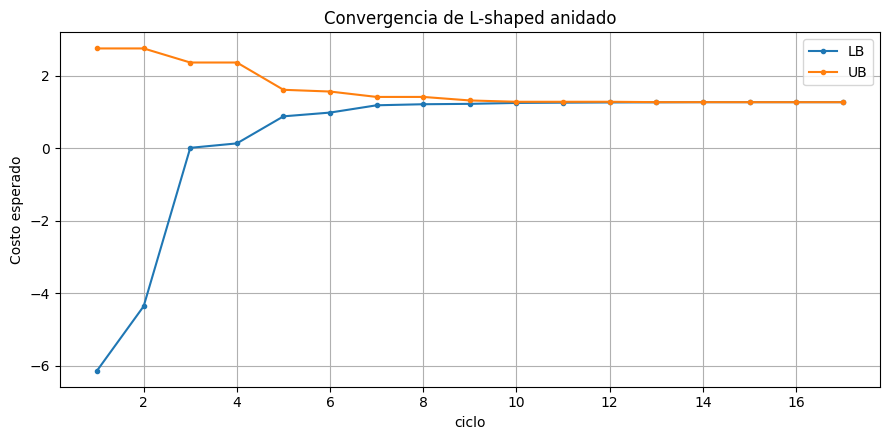

,etapa,nodo,historia,riqueza,x_SPY,x_LQD,x_GLD,f_SPY,f_LQD,f_GLD
0,1,1,Raíz,100.000000,84.227245,0.0,15.772755,0.842272,0.0,0.157728
1,2,1,AAA,106.977140,74.623589,0.0,32.353551,0.697566,0.0,0.302434
2,2,2,AAB,105.260636,77.873344,0.0,27.387292,0.739814,0.0,0.260186
3,2,3,ABA,108.249650,85.116967,0.0,23.132683,0.786302,0.0,0.213698
4,2,4,ABB,102.544290,71.417327,0.0,31.126963,0.696453,0.0,0.303547
5,2,5,BAA,93.781549,93.781549,0.0,0.000000,1.000000,0.0,0.000000
6,2,6,BAB,96.506230,81.776974,0.0,14.729255,0.847375,0.0,0.152625
7,2,7,BBA,92.605001,92.605001,0.0,0.000000,1.000000,0.0,0.000000
8,2,8,BBB,92.200958,92.200958,0.0,0.000000,1.000000,0.0,0.000000


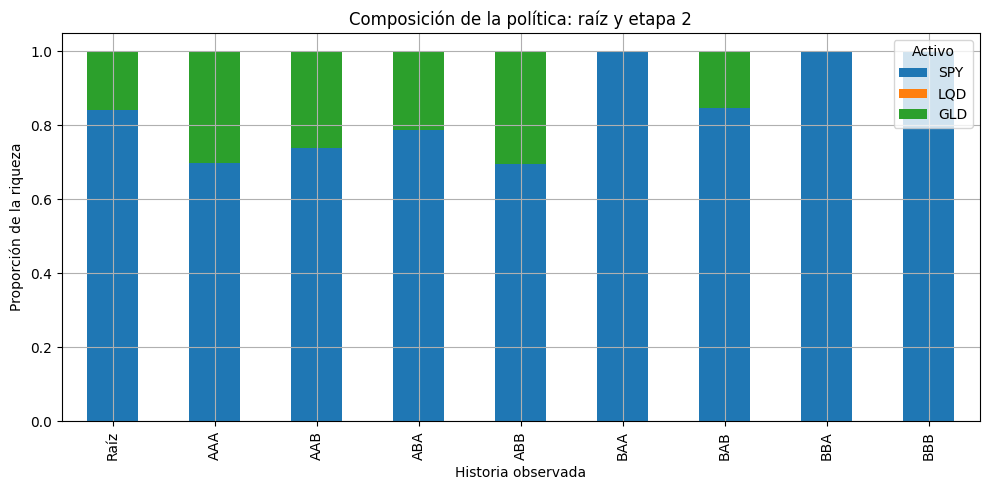

Etapa 3, ciclo 1, AAA → AAA
theta >= 155.68750000 -1.46160346 x_SPY -1.46792107 x_LQD -1.51045940 x_GLD
Punto evaluado: [114.6026469779804, 0.0, 0.0]
Valor del corte: -11.816125726235299
Etapa 1, ciclo 1, Raíz
theta >= 233.25749969 -2.37245328 x_SPY -2.34780502 x_LQD -2.39390388 x_GLD
Punto evaluado: [100.0, 0.0, 0.0]
Valor del corte: -3.987828604492762


In [ ]:
registro.plot(x="ciclo", y=["LB", "UB"], marker=".")
plt.ylabel("Costo esperado")
plt.title("Convergencia de L-shaped anidado")
guardar_figura("convergencia_LB_UB")
tabla_visible = tabla_politica.loc[tabla_politica.etapa.le(2)].copy()
display(tabla_visible)
tabla_visible.set_index("historia")[[f"f_{a}" for a in ACTIVOS]].rename(
    columns={f"f_{a}": a for a in ACTIVOS}).plot(kind="bar", stacked=True, figsize=(10, 5))
plt.ylabel("Proporción de la riqueza")
plt.xlabel("Historia observada")
plt.title("Composición de la política: raíz y etapa 2")
plt.legend(title="Activo")
guardar_figura("proporciones_raiz_etapa2")
for etapa in [3, 1]:
    corte = sol["cortes"].loc[sol["cortes"].etapa.eq(etapa)].iloc[0]
    print(f"Etapa {etapa}, ciclo {int(corte.ciclo)}, {corte.historia}")
    print(f"theta >= {corte.alpha:.8f}" + "".join(f" {corte[f'beta_{a}']:+.8f} x_{a}" for a in ACTIVOS))
    print("Punto evaluado:", [float(corte[f"xbar_{a}"]) for a in ACTIVOS])
    print("Valor del corte:", corte.valor_en_xbar)

## 8. Modelo EV y comparación dentro del árbol

El modelo de valor esperado utiliza $\overline R_i=\sum_u\widehat q_u\widehat R_i(u)$ y tiene un solo camino. Lo resolvemos y obtenemos las proporciones $g_i^t$ de cada etapa.

Luego evaluamos esas proporciones en las trayectorias del árbol: los montos cambian con la riqueza disponible, pero las proporciones EV no cambian con la historia. Denotamos por EEV el costo esperado de esta regla y por RP el costo de la política estocástica certificada dentro de la tolerancia.

$$VSS=EEV-RP.$$

Un VSS no negativo expresa el beneficio en costo esperado de la solución estocástica. No equivale directamente a un aumento de riqueza. Para evaluar cumplimiento usamos una tolerancia de $10^{-6}$ miles de dólares, equivalente a USD 0,001.

,etapa,SPY,LQD,GLD
0,1,1.0,0.0,0.0
1,2,1.0,0.0,0.0
2,3,1.0,0.0,0.0


Factores medios: {'SPY': np.float64(1.0361178659827224), 'LQD': np.float64(1.0106918129472318), 'GLD': np.float64(1.023559793752622)}
Objetivo del camino EV: -5.231421444256137


,Costo esperado,Riqueza esperada,Exceso esperado,Déficit esperado,Probabilidad de alcanzar meta,Riqueza mínima,Riqueza máxima
Estocástica,1.271199,110.417578,6.313837,1.896259,0.741215,74.991692,127.013637
Regla EV,2.753235,111.231421,7.892974,2.661552,0.599819,73.352780,127.764228


RP=1.27119912; EEV=2.75323523; VSS=1.48203610


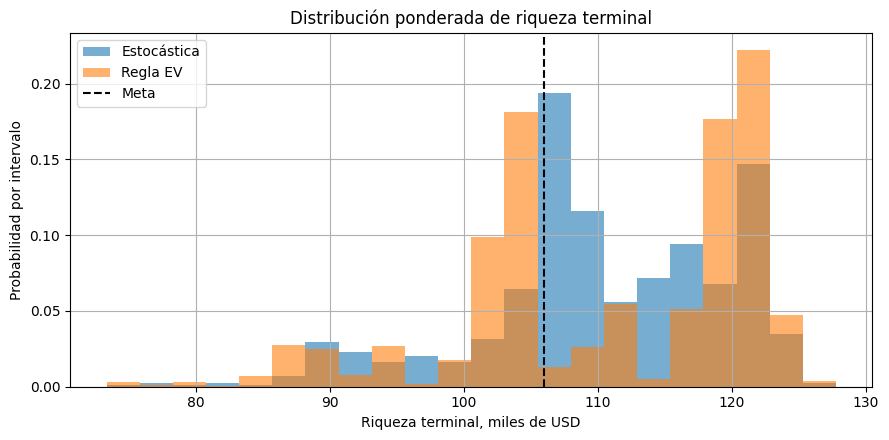

In [ ]:
R_medio = sum(q[u]*R[u] for u in estados)
ev = equivalente_determinista(["EV"], {"EV": 1.}, {"EV": R_medio})
g = {}
for t in range(1, 4):
    x = ev["politica"][tuple(["EV"]*(t-1))]
    g[t] = x/x.sum()
tabla_ev = pd.DataFrame([{"etapa": t, **dict(zip(ACTIVOS, g[t]))} for t in range(1, 4)])
display(tabla_ev)
print("Factores medios:", dict(zip(ACTIVOS, R_medio)))
print("Objetivo del camino EV:", ev["costo"])
politica_ev_arbol = {}
for nivel in niveles[:3]:
    for h in nivel:
        riqueza = B if not h else float(R[h[-1]] @ politica_ev_arbol[h[:-1]])
        x = riqueza*g[len(h)+1]
        verificar_inversion(x, riqueza)
        politica_ev_arbol[h] = x
hojas_ev = evaluar_hojas(politica_ev_arbol, estados, q, R)

def resumen_hojas(df):
    p = df.probabilidad.to_numpy()
    return {"Costo esperado": float(p @ df.costo), "Riqueza esperada": float(p @ df.riqueza),
        "Exceso esperado": float(p @ df.exceso), "Déficit esperado": float(p @ df.deficit),
        "Probabilidad de alcanzar meta": float(p @ df.cumple_meta),
        "Riqueza mínima": float(df.riqueza.min()), "Riqueza máxima": float(df.riqueza.max())}

comparacion_arbol = pd.DataFrame({"Estocástica": resumen_hojas(hojas_rp), "Regla EV": resumen_hojas(hojas_ev)}).T
RP, EEV = float(hojas_rp.probabilidad @ hojas_rp.costo), float(hojas_ev.probabilidad @ hojas_ev.costo)
VSS = EEV-RP
assert VSS >= -2*TOL_REL*max(1, abs(RP), abs(EEV))
display(comparacion_arbol)
print(f"RP={RP:.8f}; EEV={EEV:.8f}; VSS={VSS:.8f}")
guardar_tabla(tabla_ev, "proporciones_EV")
guardar_tabla(hojas_ev, "hojas_EV")
guardar_tabla(comparacion_arbol, "comparacion_dentro_arbol", index=True)
limites = np.histogram_bin_edges(np.r_[hojas_rp.riqueza, hojas_ev.riqueza], bins=22)
plt.figure()
plt.hist(hojas_rp.riqueza, bins=limites, weights=hojas_rp.probabilidad, alpha=.6, label="Estocástica")
plt.hist(hojas_ev.riqueza, bins=limites, weights=hojas_ev.probabilidad, alpha=.6, label="Regla EV")
plt.axvline(M, color="black", linestyle="--", label="Meta")
plt.xlabel("Riqueza terminal, miles de USD")
plt.ylabel("Probabilidad por intervalo")
plt.title("Distribución ponderada de riqueza terminal")
plt.legend()
guardar_figura("distribucion_riqueza_terminal")

## 9. Validación fuera de muestra: enero–septiembre de 2026

Con la política y su regla de aplicación ya guardadas, descargamos los cierres definitivos de diciembre de 2025, marzo, junio y septiembre de 2026. No modificamos probabilidades, grupos, meta ni asignaciones usando esta información.

Cada trimestre comienza con una inversión basada en la historia conocida. Al terminar usamos los tres factores reales para actualizar la riqueza y agregamos los signos observados a la historia. La terna permite escoger el nodo siguiente; no sustituye los factores reales.

Cada política acumula su propia riqueza. Si se activa el respaldo por un estado eliminado, aplicamos partes iguales durante los períodos restantes. Al terminar septiembre no rebalanceamos.

,SPY,LQD,GLD
fecha,,,
2026-03-31,0.956294,0.996189,1.085741
2026-06-30,1.151234,1.012609,0.856120
2026-09-30,1.023774,0.948156,1.033824


,politica,trimestre,fecha_inicio,fecha_fin,historia_conocida,nodo,riqueza_inicial,f_SPY,f_LQD,f_GLD,x_SPY,x_LQD,x_GLD,R_real_SPY,R_real_LQD,R_real_GLD,estado_observado_al_final,riqueza_final,respaldo_aplicado
0,Estocástica,1,2025-12-31,2026-03-31,Raíz,"(1, 1)",100.000000,0.842272,0.0,0.157728,84.227245,0.0,15.772755,0.956294,0.996189,1.085741,BBA,97.671152,False
1,Estocástica,2,2026-03-31,2026-06-30,BBA,"(2, 7)",97.671152,1.000000,0.0,0.000000,97.671152,0.0,0.000000,1.151234,1.012609,0.856120,AAB,112.442396,False
2,Estocástica,3,2026-06-30,2026-09-30,BBA → AAB,"(3, 50)",112.442396,1.000000,0.0,0.000000,112.442396,0.0,0.000000,1.023774,0.948156,1.033824,ABA,115.115609,False


,politica,trimestre,fecha_inicio,fecha_fin,historia_conocida,nodo,riqueza_inicial,f_SPY,f_LQD,f_GLD,x_SPY,x_LQD,x_GLD,R_real_SPY,R_real_LQD,R_real_GLD,estado_observado_al_final,riqueza_final,respaldo_aplicado
0,Regla EV,1,2025-12-31,2026-03-31,Raíz,Regla EV,100.000000,1.0,0.0,0.0,100.000000,0.0,0.0,0.956294,0.996189,1.085741,BBA,95.629420,False
1,Regla EV,2,2026-03-31,2026-06-30,BBA,Regla EV,95.629420,1.0,0.0,0.0,95.629420,0.0,0.0,1.151234,1.012609,0.856120,AAB,110.091884,False
2,Regla EV,3,2026-06-30,2026-09-30,BBA → AAB,Regla EV,110.091884,1.0,0.0,0.0,110.091884,0.0,0.0,1.023774,0.948156,1.033824,ABA,112.709215,False


,Riqueza terminal,Rendimiento acumulado,Exceso,Déficit,Costo realizado,Cumple meta,Respaldo utilizado
Política,,,,,,,
Estocástica,115.115609,0.151156,9.115609,0,-9.115609,1,False
Regla EV,112.709215,0.127092,6.709215,0,-6.709215,1,False


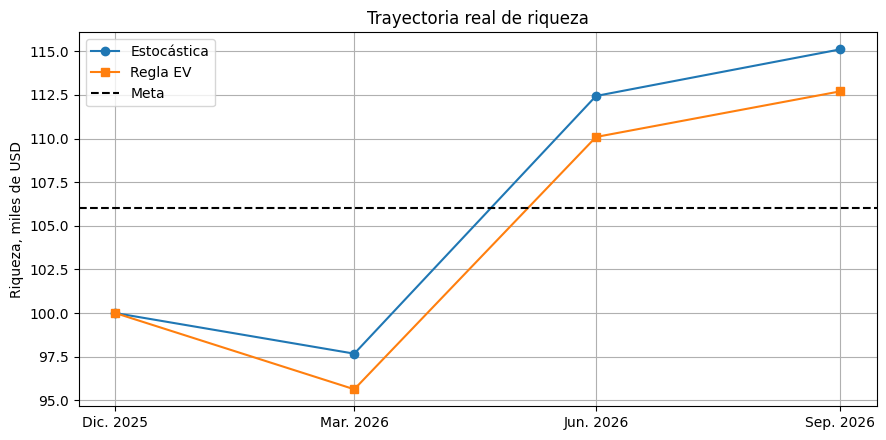

Costo EV menos costo estocástico en 2026: 2.406394129690753


In [ ]:
assert (CARPETA / "politica_fija.json").exists()
P_val = descargar_trimestrales("2025-12-01", "2026-10-01",
    pd.period_range("2025Q4", "2026Q3", freq="Q"), "validacion")
R_val = (P_val/P_val.shift(1)).iloc[1:]
r_val = R_val-1
assert P_val.shape == (4, 3) and R_val.shape == (3, 3)
guardar_tabla(R_val, "factores_reales_2026", index=True)
guardar_tabla(r_val, "rendimientos_reales_2026", index=True)
display(R_val)

def validar(nombre):
    riqueza, historia, respaldo = B, (), False
    filas, trayectoria = [], [B]
    for t, (fecha, factores) in enumerate(R_val.iterrows(), start=1):
        if nombre == "Estocástica":
            if respaldo or historia not in proporciones:
                respaldo, f, nodo = True, np.repeat(1/3, 3), "Respaldo: partes iguales"
            else:
                f, nodo = proporciones[historia].copy(), f"({t}, {ids[historia]})"
        else:
            f, nodo = g[t].copy(), "Regla EV"
        x = riqueza*f
        verificar_inversion(x, riqueza)
        valores = factores[ACTIVOS].to_numpy(dtype=float)
        final = float(valores @ x)
        observado = estado_de(valores-1)
        filas.append({"politica": nombre, "trimestre": t,
            "fecha_inicio": P_val.index[t-1].date().isoformat(), "fecha_fin": fecha.date().isoformat(),
            "historia_conocida": historia_texto(historia), "nodo": nodo, "riqueza_inicial": riqueza,
            **{f"f_{a}": f[i] for i, a in enumerate(ACTIVOS)},
            **{f"x_{a}": x[i] for i, a in enumerate(ACTIVOS)},
            **{f"R_real_{a}": valores[i] for i, a in enumerate(ACTIVOS)},
            "estado_observado_al_final": observado, "riqueza_final": final, "respaldo_aplicado": respaldo})
        riqueza = final
        trayectoria.append(final)
        historia += (observado,)
        if nombre == "Estocástica" and observado not in estados and t < 3:
            respaldo = True
    exceso, deficit = max(riqueza-M, 0), max(M-riqueza, 0)
    resumen = {"Política": nombre, "Riqueza terminal": riqueza, "Rendimiento acumulado": riqueza/B-1,
        "Exceso": exceso, "Déficit": deficit, "Costo realizado": LAM*deficit-exceso,
        "Cumple meta": int(riqueza >= M-TOL_META),
        "Respaldo utilizado": any(f["respaldo_aplicado"] for f in filas)}
    return pd.DataFrame(filas), resumen, trayectoria

cron_rp, final_rp, trayectoria_rp = validar("Estocástica")
cron_ev, final_ev, trayectoria_ev = validar("Regla EV")
display(cron_rp, cron_ev)
tabla_final = pd.DataFrame([final_rp, final_ev]).set_index("Política")
display(tabla_final)
guardar_tabla(cron_rp, "validacion_cronologica_RP")
guardar_tabla(cron_ev, "validacion_cronologica_EV")
guardar_tabla(tabla_final, "validacion_resumen", index=True)
plt.figure()
plt.plot(P_val.index, trayectoria_rp, marker="o", label="Estocástica")
plt.plot(P_val.index, trayectoria_ev, marker="s", label="Regla EV")
plt.axhline(M, color="black", linestyle="--", label="Meta")
plt.xticks(P_val.index, ["Dic. 2025", "Mar. 2026", "Jun. 2026", "Sep. 2026"])
plt.ylabel("Riqueza, miles de USD")
plt.title("Trayectoria real de riqueza")
plt.legend()
guardar_figura("validacion_riquezas")
diferencia_real = final_ev["Costo realizado"]-final_rp["Costo realizado"]
print("Costo EV menos costo estocástico en 2026:", diferencia_real)

### Interpretación de la validación

El indicador de cumplimiento toma el valor 0 o 1; no es una probabilidad estimada. La diferencia entre los costos realizados en 2026 no es el VSS y puede tener cualquier signo. Una sola trayectoria de nueve meses no permite establecer superioridad general ni significancia estadística. Los tres trimestres no son tres repeticiones independientes del experimento completo.

## 10. Composición, dominancia y variabilidad eliminada

Revisamos si algún activo tiene un factor mayor o igual que otro en todos los estados, y estrictamente mayor en alguno. Una dominancia en los promedios del árbol puede explicar su preferencia, pero no demuestra dominancia en todos los datos históricos ni en el futuro.

Cuantificamos la variabilidad que se elimina al reemplazar cada estado por su media. Utilizamos varianzas poblacionales en esta comparación para aplicar la descomposición:

$$\operatorname{Var}(R_i)=\operatorname{Var}(E[R_i\mid u])+E[\operatorname{Var}(R_i\mid u)].$$

El primer término es la variabilidad representada por el árbol y el segundo corresponde a la variabilidad interna que eliminamos.

In [ ]:
dominancias = []
for i, a in enumerate(ACTIVOS):
    for j, b_activo in enumerate(ACTIVOS):
        if i == j:
            continue
        dif = np.array([R[u][i]-R[u][j] for u in estados])
        if np.all(dif >= -1e-12) and np.any(dif > 1e-12):
            dominancias.append({"Activo dominante": a, "Activo dominado": b_activo,
                "Diferencia mínima": dif.min(), "Diferencia máxima": dif.max()})
tabla_dominancia = pd.DataFrame(dominancias, columns=[
    "Activo dominante", "Activo dominado", "Diferencia mínima", "Diferencia máxima"])
display(tabla_dominancia)
guardar_tabla(tabla_dominancia, "dominancia_factores")
variabilidad = []
for i, a in enumerate(ACTIVOS):
    media = float(R_medio[i])
    var_total = float(np.mean((R_cal[a].to_numpy()-media)**2))
    var_entre = sum(q[u]*(R[u][i]-media)**2 for u in estados)
    var_interna = max(0., var_total-var_entre)
    variabilidad.append({"Activo": a, "Desv_histórica_poblacional": np.sqrt(var_total),
        "Desv_factores_del_árbol": np.sqrt(var_entre), "Varianza_interna_eliminada": var_interna,
        "Fracción_varianza_eliminada": var_interna/var_total if var_total > 0 else 0})
tabla_variabilidad = pd.DataFrame(variabilidad).set_index("Activo")
display(tabla_variabilidad)
guardar_tabla(tabla_variabilidad, "variabilidad_eliminada", index=True)
sin_inversion = [a for a in ACTIVOS if tabla_politica[f"x_{a}"].abs().max() <= TOL_FACT]
print("Activos sin inversión en todos los nodos:", sin_inversion or "Ninguno")

,Activo dominante,Activo dominado,Diferencia mínima,Diferencia máxima


,Desv_histórica_poblacional,Desv_factores_del_árbol,Varianza_interna_eliminada,Fracción_varianza_eliminada
Activo,,,,
SPY,0.073783,0.060009,0.001843,0.338515
LQD,0.036719,0.030375,0.000426,0.315692
GLD,0.076326,0.062597,0.001907,0.327381


Activos sin inversión en todos los nodos: ['LQD']


### 10.1. Trayectoria representativa frente a trayectoria observada

Comparamos la riqueza real con la trayectoria del árbol que tiene los mismos signos. Las proporciones se seleccionan por la misma historia, pero los factores reales y representativos pueden ser distintos. Esa diferencia se acumula a lo largo del horizonte.

In [ ]:
historia, riqueza_arbol, contraste = (), B, []
for t, (_, fila) in enumerate(R_val.iterrows(), start=1):
    u = estado_de(fila.to_numpy()-1)
    if historia not in proporciones or u not in R:
        break
    riqueza_arbol *= float(R[u] @ proporciones[historia])
    contraste.append({"Trimestre": t, "Estado observado": u,
        "Riqueza representativa del árbol": riqueza_arbol,
        "Riqueza real estocástica": trayectoria_rp[t],
        "Diferencia real menos árbol": trayectoria_rp[t]-riqueza_arbol})
    historia += (u,)
tabla_contraste = pd.DataFrame(contraste)
display(tabla_contraste)
guardar_tabla(tabla_contraste, "contraste_trayectoria_arbol_real")

,Trimestre,Estado observado,Riqueza representativa del árbol,Riqueza real estocástica,Diferencia real menos árbol
0,1,BBA,92.605001,97.671152,5.066151
1,2,AAB,99.016721,112.442396,13.425675
2,3,ABA,107.443043,115.115609,7.672566


## 11. Síntesis y conclusiones

La comparación reducida permite comprobar la implementación y la brecha del árbol completo certifica la solución dentro de la tolerancia establecida. La siguiente tabla reúne la evidencia numérica de la ejecución.

Interpretamos por separado el costo esperado del árbol y el costo realizado en 2026. El primero considera todos los escenarios representados; el segundo describe únicamente lo ocurrido en una trayectoria.

Los cambios de composición se leen en la tabla cronológica: cada rebalanceo utiliza lo observado hasta ese momento. La tabla de dominancia y los activos sin inversión ayudan a explicar las asignaciones. Si un activo domina a otro en todos los estados representativos, puede existir una solución óptima que prescinda del dominado; esto no implica que todas las soluciones óptimas deban hacerlo.

La agrupación por signos simplifica los datos y elimina dispersión dentro de los estados. Esa reducción puede hacer que un activo parezca más seguro de lo que indican sus observaciones individuales. Además, la independencia temporal impide representar dependencias entre trimestres.

La aplicación por proporciones conserva la factibilidad con riqueza real, pero no garantiza optimalidad fuera del árbol. La validación permite describir el desempeño observado y verificar la aplicación cronológica; no permite generalizar superioridad ni estimar con confianza una probabilidad de éxito.

In [ ]:
ultima = registro.iloc[-1]
sintesis = pd.DataFrame([
    ["Diferencia relativa de verificación reducida", diferencia_relativa],
    ["Ciclos del árbol completo", int(ultima.ciclo)],
    ["Cortes del árbol completo", int(ultima.cortes)],
    ["Tiempo en segundos", ultima.segundos],
    ["LB final", ultima.LB], ["UB final", ultima.UB],
    ["Brecha relativa final", ultima.brecha_relativa],
    ["RP", RP], ["EEV", EEV], ["VSS", VSS],
    ["Riqueza real estocástica", final_rp["Riqueza terminal"]],
    ["Riqueza real EV", final_ev["Riqueza terminal"]],
    ["Diferencia de costos realizados EV menos RP", diferencia_real]
], columns=["Indicador", "Valor"])
display(sintesis)
display(cron_rp[["trimestre", "historia_conocida", "nodo"]+[f"f_{a}" for a in ACTIVOS]])
guardar_tabla(sintesis, "sintesis_resultados")

,Indicador,Valor
0,Diferencia relativa de verificación reducida,7.021598e-14
1,Ciclos del árbol completo,1.700000e+01
2,Cortes del árbol completo,1.241000e+03
3,Tiempo en segundos,2.354660e+01
4,LB final,1.271199e+00
5,UB final,1.271199e+00
6,Brecha relativa final,5.778194e-12
7,RP,1.271199e+00
8,EEV,2.753235e+00
9,VSS,1.482036e+00


,trimestre,historia_conocida,nodo,f_SPY,f_LQD,f_GLD
0,1,Raíz,"(1, 1)",0.842272,0.0,0.157728
1,2,BBA,"(2, 7)",1.000000,0.0,0.000000
2,3,BBA → AAB,"(3, 50)",1.000000,0.0,0.000000


## 12. Reproducibilidad y exportación

Guardamos cierres, resultados, figuras, cortes y versiones del entorno. Yahoo puede revisar sus ajustes históricos, por lo que conviene conservar los CSV de esta ejecución. El ZIP no incorpora automáticamente el notebook ni sustituye el informe PDF.

Para repetir la ejecución con los cierres conservados, se pueden sustituir las llamadas de descarga por `pd.read_csv(ruta, index_col="fecha", parse_dates=["fecha"])`, manteniendo el registro de la consulta original. Las fechas y dimensiones deben seguir cumpliendo las verificaciones.

In [ ]:
guardar_tabla(pd.DataFrame(REGISTRO_DESCARGAS), "registro_descargas")
paquetes = ["numpy", "pandas", "scipy", "matplotlib", "yfinance", "pandas_market_calendars"]
versiones = {p: importlib.metadata.version(p) for p in paquetes}
(CARPETA / "requirements.txt").write_text("\n".join(f"{p}=={v}" for p, v in versiones.items()), encoding="utf-8")
metadatos = {"python": sys.version, "fecha_ejecucion_UTC": datetime.now(timezone.utc).isoformat(),
    "versiones": versiones, "componentes_aleatorios": False, "semilla": "No aplica",
    "tolerancia_relativa": TOL_REL, "tolerancia_meta_miles_USD": TOL_META,
    "estados_reducidos": estados_red, "estados_ausentes": ausentes,
    "RP": RP, "EEV": EEV, "VSS": VSS,
    "LB_final": float(ultima.LB), "UB_final": float(ultima.UB)}
(CARPETA / "metadatos.json").write_text(json.dumps(metadatos, ensure_ascii=False, indent=2), encoding="utf-8")
readme = "\n".join([
    "PRÁCTICA 2 — OPTIMIZACIÓN ESTOCÁSTICA",
    "Abrir el notebook en Colab y ejecutar todas las celdas en orden.",
    "La consulta a Yahoo requiere internet. No reemplazar precios faltantes ni usar datos ficticios.",
    "Calibración hasta 2025; política fija antes de descargar la validación 2026.",
    "No hay componentes aleatorios. Las versiones están en requirements.txt.",
    "Conservar los CSV y registro_descargas.csv: Yahoo puede revisar precios ajustados.",
    "Las cifras monetarias se expresan en miles de dólares.",
    "El ZIP contiene datos, tablas, cortes y figuras de esta ejecución.",
    "Descargar aparte el notebook ejecutado: Archivo > Descargar > Descargar .ipynb.",
    "Entregar también el informe PDF de máximo 15 páginas, sin contar anexos."])
(CARPETA / "README.txt").write_text(readme, encoding="utf-8")
ruta_zip = shutil.make_archive("/content/practica2_resultados", "zip", root_dir=CARPETA)
print("Archivos generados:", len(list(CARPETA.iterdir())))
print("ZIP:", ruta_zip)

Archivos generados: 39
ZIP: /content/practica2_resultados.zip


### Descarga de resultados

Ejecutamos esta celda en Colab para descargar el ZIP. Después guardamos el notebook con sus salidas desde el menú Archivo.

In [ ]:
from google.colab import files
files.download(ruta_zip)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Referencias

- Yahoo Finance. Históricos de [SPY](https://finance.yahoo.com/quote/SPY/history/), [LQD](https://finance.yahoo.com/quote/LQD/history/) y [GLD](https://finance.yahoo.com/quote/GLD/history/). Campo Adj Close; fecha de consulta en el registro generado.
- [yfinance](https://ranaroussi.github.io/yfinance/). Documentación de la herramienta de acceso a Yahoo Finance.
- [SciPy: linprog con HiGHS](https://docs.scipy.org/doc/scipy/reference/optimize.linprog-highs.html). Solución de LP y multiplicadores duales.
- [pandas_market_calendars](https://pandas-market-calendars.readthedocs.io/). Calendarios de sesiones bursátiles.